# Importing Packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Load the RFM table

In [2]:
rfm = pd.read_parquet("../data/processed/rfm_segments.parquet")
print(rfm.shape)


(5852, 12)


# Log-transform R, F and M

### creating the log-transformed features

In [3]:
X = np.log1p(rfm[['Recency', 'Frequency', 'Monetary']])
X.head()

,Recency,Frequency,Monetary
0,6.272877,1.098612,5.137914
1,1.098612,2.197225,8.501578
2,4.330733,1.791759,7.414211
3,2.995732,1.386294,8.210584
4,5.739793,0.693147,5.688330


### comparing skewness before and after

In [4]:
skew_check = pd.DataFrame({
    'Before log': rfm[['Recency', 'Frequency', 'Monetary']].skew(),
    'After log': X.skew()
}).round(2)
skew_check

,Before log,After log
Recency,0.89,-0.49
Frequency,12.04,1.00
Monetary,26.12,0.25


### Visualizing using histograms

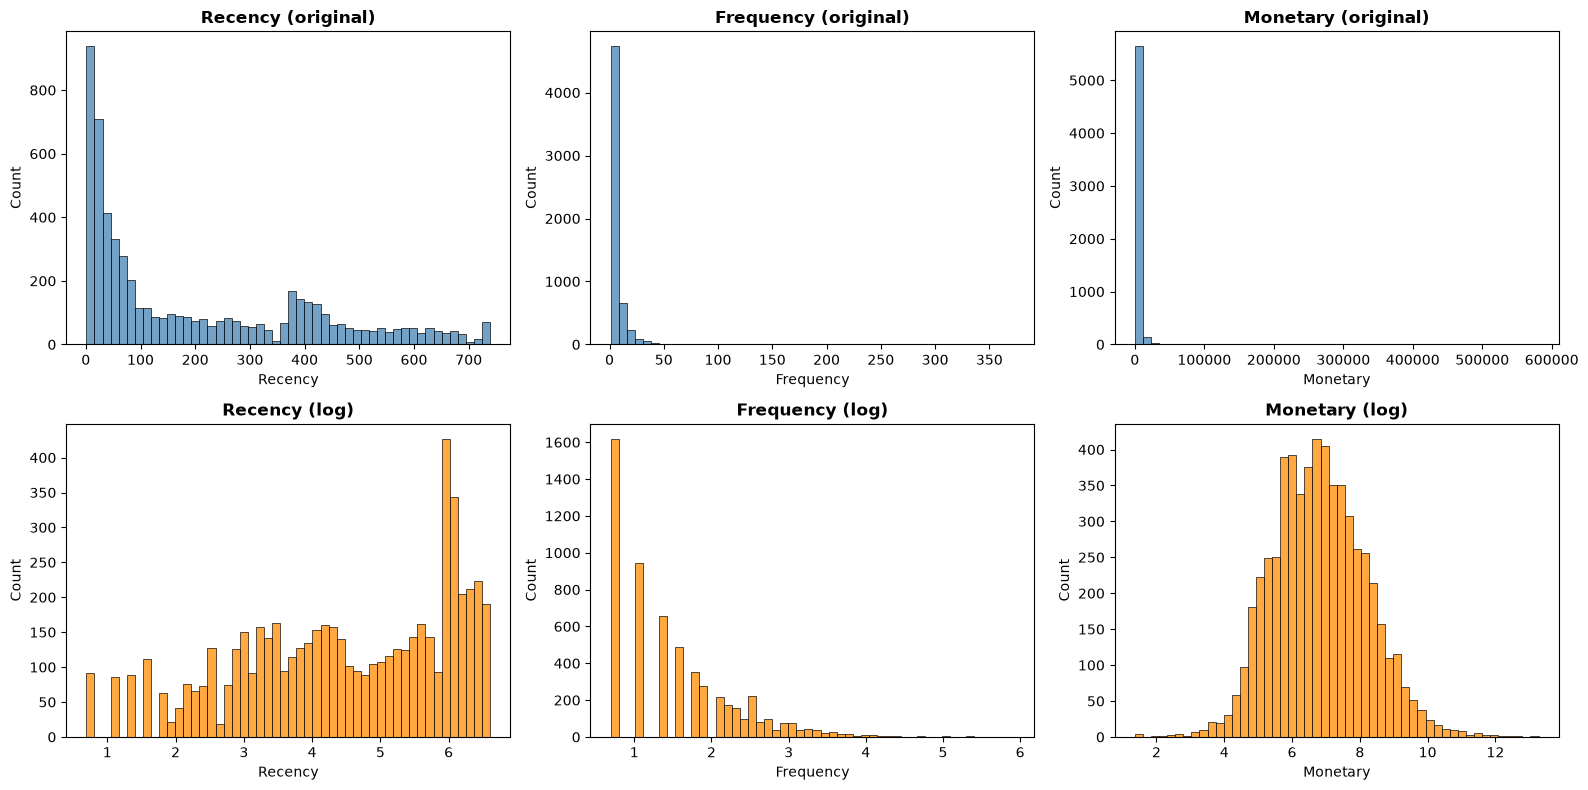

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, col in enumerate(['Recency', 'Frequency', 'Monetary']):
    sns.histplot(rfm[col], bins=50, ax=axes[0, i], color='steelblue')
    axes[0, i].set_title(f'{col} (original)', fontweight='bold')
    sns.histplot(X[col], bins=50, ax=axes[1, i], color='darkorange')
    axes[1, i].set_title(f'{col} (log)', fontweight='bold')
plt.tight_layout()
plt.show()

### Insights:
- Before log, Monetary (26.12) and Frequency (12.04) had very high skew. This is because some wholesale customers buy much more than others. Recency (0.89) was only a little skewed.
- After log, Monetary became 0.25 and Recency became -0.49, so now they are almost balanced.
- Frequency came down from 12.04 to 1.00. It is still a bit skewed because many customers ordered only 1 or 2 times, but it is much better now.
- I did this because K-Means uses distance. If I didn't use log, the big customers would affect the clusters too much.

# Scaling

In [6]:
scaler = StandardScaler()

In [7]:
x_scaled=scaler.fit_transform(X)

In [8]:
print(x_scaled.mean(axis=0).round(2))
print(x_scaled.std(axis=0).round(2))

[0. 0. 0.]
[1. 1. 1.]


In [9]:
pd.DataFrame(x_scaled, columns=X.columns).head()

,Recency,Frequency,Monetary
0,1.170814,-0.555140,-1.208596
1,-2.151626,0.804938,1.229283
2,-0.076253,0.302973,0.441194
3,-0.933469,-0.198991,1.018380
4,0.828516,-1.057104,-0.809671


### Insights:
- After log, the columns were still on different ranges. Monetary values were much bigger than Frequency values, so Monetary would have more effect on the distance in K-Means.
- I used StandardScaler to bring all three columns to the same scale.
- After scaling, the mean of each column is 0 and the standard deviation is 1, so now Recency, Frequency and Monetary are treated equally.

## Choosing the number of clusters (k)
- K-Means needs me to decide how many clusters to make, so I tried k from 2 to 10.
- For each k, I checked two things:
  - Inertia (elbow method): how close customers are to their cluster centre. I look for the point where the line stops dropping fast.
  - Silhouette score: how well the clusters are separated. Higher is better.
- Then I pick the k that has a clear elbow and a good silhouette score.

In [10]:
k_values = range(2, 11)

In [11]:
inertias = [] 
silhouettes = []

In [12]:
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(x_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(x_scaled, labels))

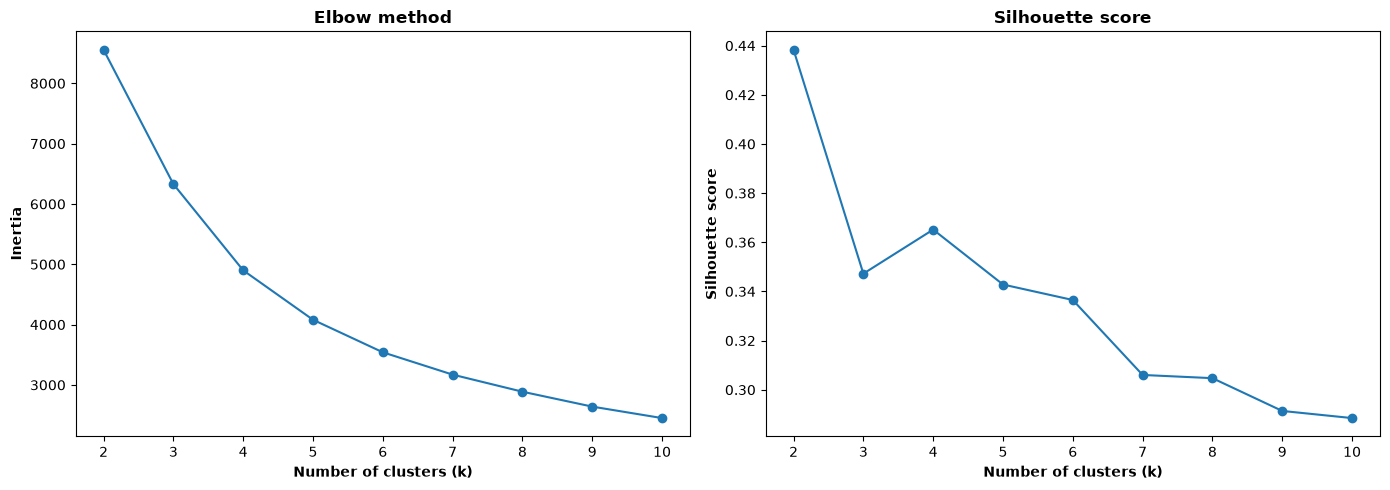

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(k_values, inertias, marker='o')
axes[1].plot(k_values, silhouettes, marker='o')
axes[0].set_title('Elbow method', fontweight='bold')
axes[0].set_xlabel('Number of clusters (k)',fontweight='bold')
axes[0].set_ylabel('Inertia',fontweight='bold')

axes[1].set_title('Silhouette score', fontweight='bold')
axes[1].set_xlabel('Number of clusters (k)' , fontweight='bold')
axes[1].set_ylabel('Silhouette score',fontweight='bold')
plt.tight_layout()
plt.show()

In [14]:
pd.DataFrame({'k': list(k_values), 'Inertia': inertias, 'Silhouette': silhouettes}).round(3)

,k,Inertia,Silhouette
0,2,8557.175,0.438
1,3,6330.325,0.347
2,4,4899.974,0.365
3,5,4080.557,0.343
4,6,3541.240,0.337
5,7,3170.943,0.306
6,8,2887.623,0.305
7,9,2640.585,0.291
8,10,2450.447,0.288


### Insights:
- In the elbow chart, inertia drops a lot from k = 2 to k = 4, and after k = 4 the line starts to flatten. So the elbow is at k = 4.
- The highest silhouette score is at k = 2 (0.438). But only 2 groups is too simple, it just splits customers into good and bad.
- At k = 4 the silhouette score (0.365) goes up again and is higher than k = 3 (0.347). This means 4 clusters are better separated than 3.
- So I chose k = 4, because the elbow is there and the silhouette score is still good.

## Building the final K-Means model
- I chose k = 4 from the elbow and silhouette charts.
- Now I build the final model and give each customer a cluster number.

In [15]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

In [16]:
rfm['Cluster'] = kmeans.fit_predict(x_scaled)

In [17]:
rfm['Cluster'].value_counts().sort_index() # Counting how many customers are in each cluster

Cluster
0    1246
1    1970
2    1453
3    1183
Name: count, dtype: int64

### Insights:
- The 4 clusters have 1,246, 1,970, 1,453 and 1,183 customers.
- Cluster 1 is the biggest (1,970) and cluster 3 is the smallest (1,183), but all clusters have enough customers to be meaningful groups.

## Understanding the clusters
- The cluster numbers don't mean anything by themselves.
- I make a summary of each cluster to see what kind of customers are in it, and then give each cluster a name.

In [18]:
profile = rfm.groupby('Cluster').agg(
    Customers=('Customer ID', 'count'),
    Median_Recency=('Recency', 'median'),
    Median_Frequency=('Frequency', 'median'),
    Median_Monetary=('Monetary', 'median'),
    Total_Revenue=('Monetary', 'sum'),
)

In [19]:
profile['Revenue_Share_%'] = (profile['Total_Revenue'] / profile['Total_Revenue'].sum() * 100).round(1)
profile.round(1)

,Customers,Median_Recency,Median_Frequency,Median_Monetary,Total_Revenue,Revenue_Share_%
Cluster,,,,,,
0,1246,24.0,3.0,720.4,1048418.9,6.2
1,1970,401.0,1.0,274.4,623916.1,3.7
2,1453,184.0,4.0,1452.9,2790445.4,16.6
3,1183,17.0,13.0,4905.5,12360149.2,73.5


### Insights:
- **Champions (cluster 3):** bought 17 days ago, about 13 orders, spent about £4,906.
- These are **my best customers.**
- **New Customers (cluster 0):** bought 24 days ago but only about 3 orders and £720 spent.
-  They are **active but still new**.
- **At Risk (cluster 2):** spent well (about £1,453 and 4 orders) but last bought 184 days ago.
- They were **good customers who are slipping away**.
- **Lost Customers (cluster 1):** last bought 401 days ago with only 1 order and £274 spent.
- This is the biggest group (1,970 customers) but brings only 3.7% of revenue.
- The Champions cluster has only 20% of customers but brings in 73.5% of the total revenue, so it is the most valuable group for the business.

In [20]:
cluster_names = {0: 'New Customers', 1: 'Lost Customers', 2: 'At Risk', 3: 'Champions'}
rfm['ClusterName'] = rfm['Cluster'].map(cluster_names)
rfm['ClusterName'].value_counts()

ClusterName
Lost Customers    1970
At Risk           1453
New Customers     1246
Champions         1183
Name: count, dtype: int64

## Visualising the clusters
- I have 3 features, so I use PCA to turn them into 2 so I can draw them on a normal chart.
- PCA is only used for the picture. The clusters were already made using all 3 features.

In [21]:
pca = PCA(n_components=2)

In [22]:
coords = pca.fit_transform(x_scaled)

In [23]:
print(pca.explained_variance_ratio_.sum().round(3))

0.952


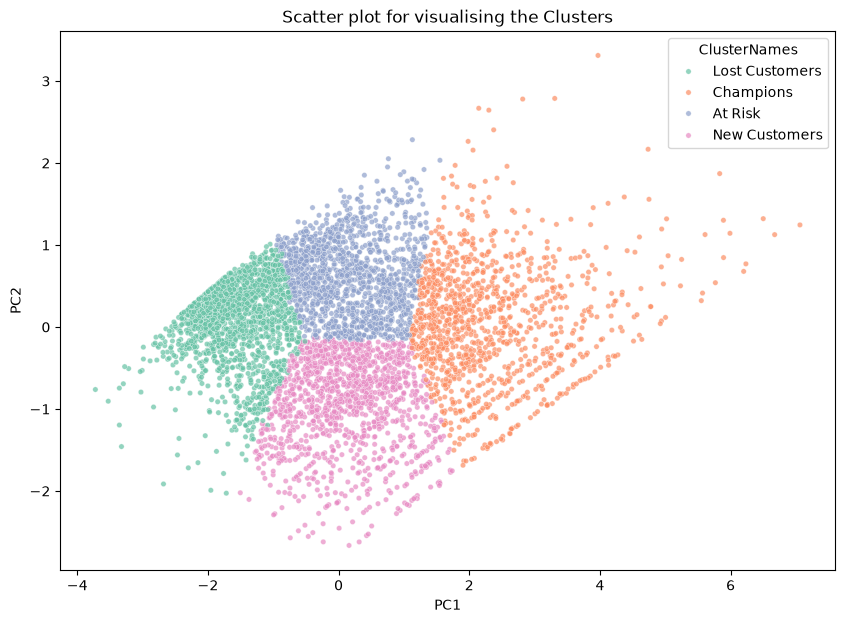

In [24]:
plt.figure(figsize=(10, 7))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=rfm['ClusterName'], palette='Set2', s=15, alpha=0.7)
plt.title("Scatter plot for visualising the Clusters")
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(title='ClusterNames') 
plt.show()


In [25]:
profile['ClusterName'] = profile.index.map(cluster_names)

# Visualizing using Bar chart


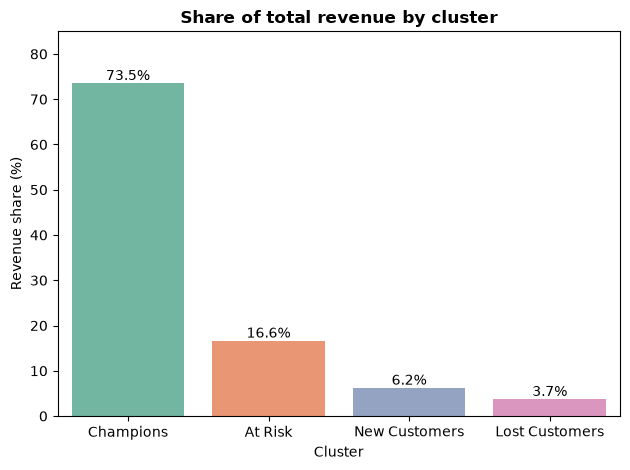

In [26]:
ax = sns.barplot(x='ClusterName', y='Revenue_Share_%',
                 data=profile.sort_values('Revenue_Share_%', ascending=False),
                 hue='ClusterName', palette='Set2', legend=False)

for bars in ax.containers:
    ax.bar_label(bars, fmt='%.1f%%')

plt.title('Share of total revenue by cluster', fontweight='bold')
plt.xlabel('Cluster')
plt.ylabel('Revenue share (%)')
plt.ylim(0, 85)
plt.tight_layout()
plt.show()

### Insights:
- PCA kept 95.2 % of the information in 2 components, so this chart is a good picture of the clusters.
- The 4 clusters are clearly separate, with only small overlaps at the edges where customers are in between groups.
- From left to right the chart goes from Lost Customers to Champions, so PC1 shows overall customer value.
- At Risk and New Customers are in the middle, but At Risk is higher up because they bought more in the past but not recently.
- Champions are the most spread out. A few dots far on the right are very big customers who buy much more than everyone else.
- The bar chart shows Champions bring in 73.5% of revenue, which is more than all the other clusters together.

# Comparison

In [27]:
comparison = pd.crosstab(rfm['Segment'], rfm['ClusterName'], normalize='index') * 100
comparison.round(1)

ClusterName,At Risk,Champions,Lost Customers,New Customers
Segment,,,,
At Risk,75.4,1.8,22.8,0.0
Champions,7.9,71.8,0.0,20.3
Lost,5.6,0.0,94.4,0.0
Loyal,48.6,8.9,4.1,38.3
Need Attention,9.9,0.0,69.9,20.2
New Customers,0.4,0.0,8.9,90.7


# Visualising using Heat Map

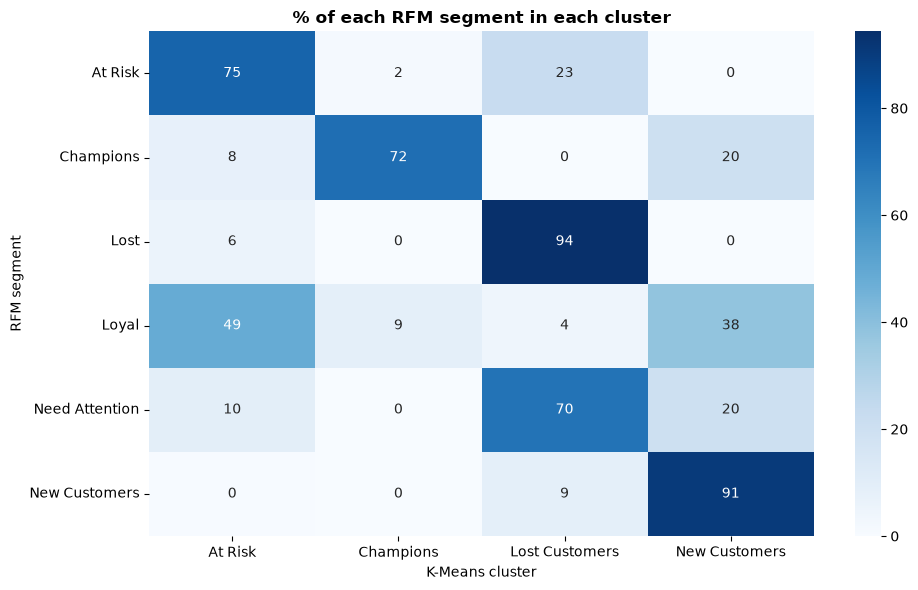

In [28]:
plt.figure(figsize=(10, 6))
sns.heatmap(comparison, annot=True, fmt='.0f', cmap='Blues')
plt.title('% of each RFM segment in each cluster', fontweight='bold')
plt.xlabel('K-Means cluster')
plt.ylabel('RFM segment')
plt.tight_layout()
plt.show()

### Insights:
- Most of my RFM segments match the clusters well. 94% of Lost customers went to the Lost cluster, 91% of New Customers went to the New Customers cluster, 75% of At Risk went to At Risk, and 72% of Champions went to Champions.
- Loyal customers got split the most. About half went to At Risk, 38% went to New Customers and only 9% went to Champions. So K-Means thinks my Loyal group has different types of customers in it.
- 70% of Need Attention customers went to Lost Customers. So K-Means thinks most of them are already lost.
- 20% of my Champions went to New Customers. They bought recently but did not spend as much, so K-Means did not put them with the big spenders.
- I think the results are different because my rules only used Recency and Frequency, but K-Means also used Monetary.

## Saving the model and results
- I save the scaler, the K-Means model and the cluster names so I can use them in the Streamlit app.
- I also save the RFM table with the cluster for each customer.

In [29]:
os.makedirs("../models", exist_ok=True)

In [30]:
joblib.dump(scaler, "../models/rfm_scaler.pkl")
joblib.dump(kmeans, "../models/kmeans.pkl")
joblib.dump(cluster_names, "../models/cluster_names.pkl")

['../models/cluster_names.pkl']

In [31]:
rfm.to_parquet("../data/processed/rfm_clusters.parquet", index=False)

In [32]:
print("Saved:", rfm.shape)

Saved: (5852, 14)


## Summary
- I used K-Means to group customers using Recency, Frequency and Monetary. First I used log to reduce the skew, then StandardScaler so all three columns are treated equally.
- I tested k from 2 to 10 and chose k = 4, because the elbow is at 4 and the silhouette score (0.365) is better than k = 3.
- The 4 clusters are Champions, New Customers, At Risk and Lost Customers. PCA kept 95.2% of the information, and the chart shows the clusters are clearly separate.
- Champions are only 20% of customers but bring in 73.5% of the revenue. Lost Customers are the biggest group (1,970) but bring only 3.7%.
- Most of my RFM segments matched the clusters well, but Loyal and Need Attention were split. This is because my rules only used Recency and Frequency, but K-Means also used Monetary.
- I saved the scaler, the K-Means model and the cluster names to use in the Streamlit app.
- Next, in Phase 4, I will train models to predict which customers will churn.